# 🚗 Used Car Price Predictor: Polynomial Regression

**Goal:** Predict the selling price (in Indian rupees) of a used car from its age, kilometres driven, engine size, power, brand, fuel type, transmission, and seller type.

**Why polynomial regression?** A car’s price depends on its age, mileage, power, and brand in curved, overlapping ways. A plain linear model can miss these patterns, but polynomial terms let the model bend to follow them.

**Dataset:** CarDekho used-car listings (about 15,000 cars, prices in INR)

**Models compared:** Polynomial regression of degree 1 (a straight line), 2, 3, and 4, each with Ridge regularization

**Tools:** Python, pandas, NumPy, Matplotlib, Seaborn, scikit-learn

**Workflow:** Load → Clean → EDA → Train/test split → Compare polynomial degrees (with cross-validation) → Residual analysis → Export the model for a website

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
import os

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OneHotEncoder
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

sns.set_style("whitegrid")
RANDOM_STATE = 42
LAKH = 100_000          # 1 lakh = 100,000 rupees

NUM_COLS = ["vehicle_age", "km_driven", "engine", "max_power"]
CAT_COLS = ["brand", "fuel_type", "transmission_type", "seller_type"]

## 1. Load the Data

In [2]:
URL = "https://raw.githubusercontent.com/manishkr1754/CarDekho_Used_Car_Price_Prediction/main/notebooks/data/cardekho_dataset.csv"

try:
    df = pd.read_csv(URL)
except Exception:
    # If the download fails, upload the CSV file by hand
    print("Download failed. Please choose the CSV file from your computer.")
    from google.colab import files
    uploaded = files.upload()
    df = pd.read_csv(list(uploaded.keys())[0])

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
df.head()

Shape: (15411, 14)
Columns: ['Unnamed: 0', 'car_name', 'brand', 'model', 'vehicle_age', 'km_driven', 'seller_type', 'fuel_type', 'transmission_type', 'mileage', 'engine', 'max_power', 'seats', 'selling_price']


,Unnamed: 0,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,4,Ford Ecosport,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000


In [3]:
needed = ["brand", "vehicle_age", "km_driven", "engine", "max_power",
          "fuel_type", "transmission_type", "seller_type", "selling_price"]

missing = [c for c in needed if c not in df.columns]
assert not missing, f"These columns are missing: {missing}. Check the column names printed above."

df = df[needed].copy()
print(df.isnull().sum())
df.describe().T

brand                0
vehicle_age          0
km_driven            0
engine               0
max_power            0
fuel_type            0
transmission_type    0
seller_type          0
selling_price        0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
vehicle_age,15411.0,6.036338,3.013291,0.0,4.0,6.0,8.0,29.0
km_driven,15411.0,55616.480631,51618.548422,100.0,30000.0,50000.0,70000.0,3800000.0
engine,15411.0,1486.057751,521.106696,793.0,1197.0,1248.0,1582.0,6592.0
max_power,15411.0,100.588254,42.972979,38.4,74.0,88.5,117.3,626.0
selling_price,15411.0,774971.116410,894128.363263,40000.0,385000.0,556000.0,825000.0,39500000.0


**Observations:** The `max` values of `selling_price` and `km_driven` are far above the typical range, so a few expensive cars and cars with extreme mileage could distort the model. They are handled in the cleaning step.

## 2. Data Cleaning

Changes made:
- Remove missing values and duplicate rows
- Keep mainstream cars: price up to 50 lakh (5,000,000 INR) and up to 300,000 km driven
- Remove rows with an engine size or power of zero
- Group rare brands (fewer than 30 cars) into one `Other` category
- Create `log_price`, the natural log of the price, which becomes the **target** (explained in the next section)

In [4]:
before = len(df)

df = df.dropna().drop_duplicates()
df = df[
    (df["selling_price"] <= 5_000_000)
    & (df["km_driven"] <= 300_000)
    & (df["engine"] > 0)
    & (df["max_power"] > 0)
].copy()

# Group rare brands
brand_counts = df["brand"].value_counts()
rare_brands = list(brand_counts[brand_counts < 30].index)
df["brand"] = df["brand"].replace(rare_brands, "Other")

df["log_price"] = np.log(df["selling_price"])

print(f"Rows before: {before} | after: {len(df)} | removed: {before - len(df)}")
print("Brands:", df["brand"].nunique())

Rows before: 15411 | after: 15064 | removed: 347
Brands: 19


## 3. Exploratory Data Analysis (EDA)

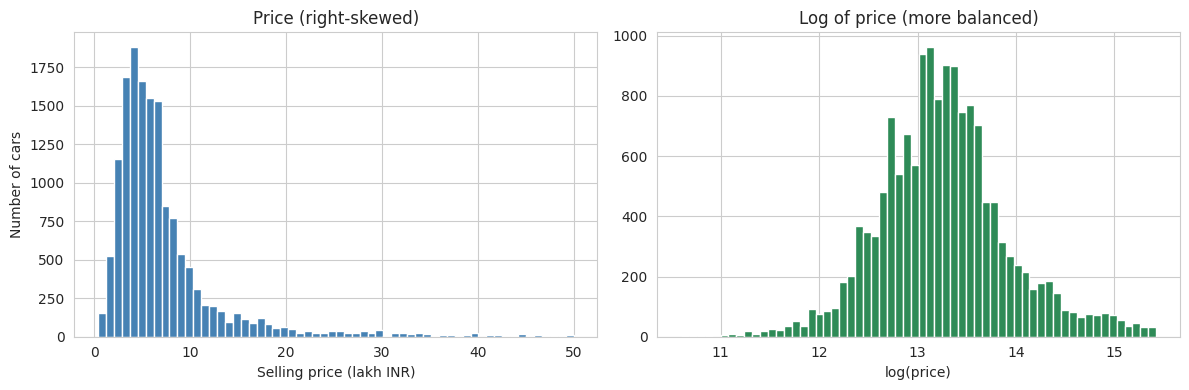

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].hist(df["selling_price"] / LAKH, bins=60, color="steelblue", edgecolor="white")
ax[0].set_xlabel("Selling price (lakh INR)")
ax[0].set_ylabel("Number of cars")
ax[0].set_title("Price (right-skewed)")

ax[1].hist(df["log_price"], bins=60, color="seagreen", edgecolor="white")
ax[1].set_xlabel("log(price)")
ax[1].set_title("Log of price (more balanced)")

plt.tight_layout()
plt.show()

**Insight:** Most cars are cheap and a few are very expensive, so the price is right-skewed. Taking the logarithm makes the distribution much more balanced. The model will predict `log_price`, and the prediction is converted back to rupees afterwards. This also means errors are measured relative to the price, so a 1 lakh mistake on a cheap car counts more than on an expensive one, which is what we want.

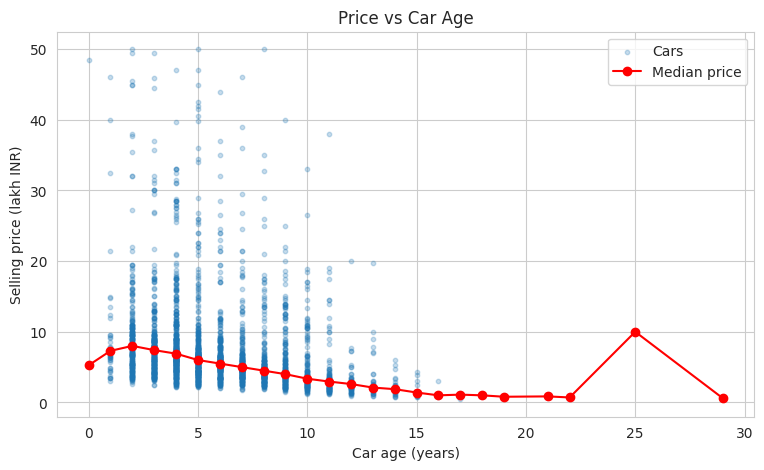

In [6]:
sample = df.sample(3000, random_state=RANDOM_STATE)
median_by_age = df.groupby("vehicle_age")["selling_price"].median() / LAKH

plt.figure(figsize=(9, 5))
plt.scatter(sample["vehicle_age"], sample["selling_price"] / LAKH, alpha=0.25, s=10, label="Cars")
plt.plot(median_by_age.index, median_by_age.values, color="red", marker="o", label="Median price")
plt.xlabel("Car age (years)")
plt.ylabel("Selling price (lakh INR)")
plt.title("Price vs Car Age")
plt.legend()
plt.show()

**Insight:** The median price is highest for cars about 2 years old, then falls steadily with age and flattens after about 15 years. The jump at 25 years comes from a single car, so ignore it. The relationship is curved, not a straight line.

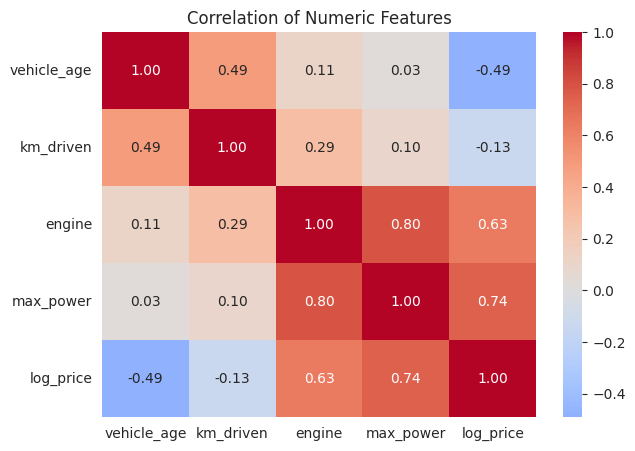

In [7]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[NUM_COLS + ["log_price"]].corr(), annot=True, cmap="coolwarm", fmt=".2f", center=0)
plt.title("Correlation of Numeric Features")
plt.show()

**Insight:** Engine size and power are strongly positively related to price, and car age is negatively related. Engine and power are also strongly correlated with each other, so they carry overlapping information.

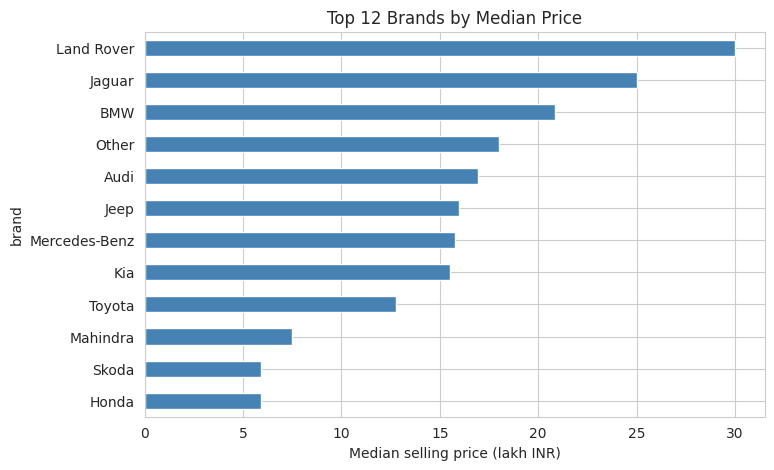

In [8]:
top_brands = df.groupby("brand")["selling_price"].median().sort_values(ascending=False).head(12) / LAKH

plt.figure(figsize=(8, 5))
top_brands.sort_values().plot(kind="barh", color="steelblue")
plt.xlabel("Median selling price (lakh INR)")
plt.title("Top 12 Brands by Median Price")
plt.show()

## 4. Train/Test Split

In [9]:
X = df[NUM_COLS + CAT_COLS]
y = df["log_price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (12051, 8) | Test: (3013, 8)


## 5. Polynomial Regression: A Simple Example with One Feature

To see the idea clearly, first predict the price from **car age only**, using polynomial degrees 1, 2, and 3. Degree 1 is a straight line, and higher degrees can bend.

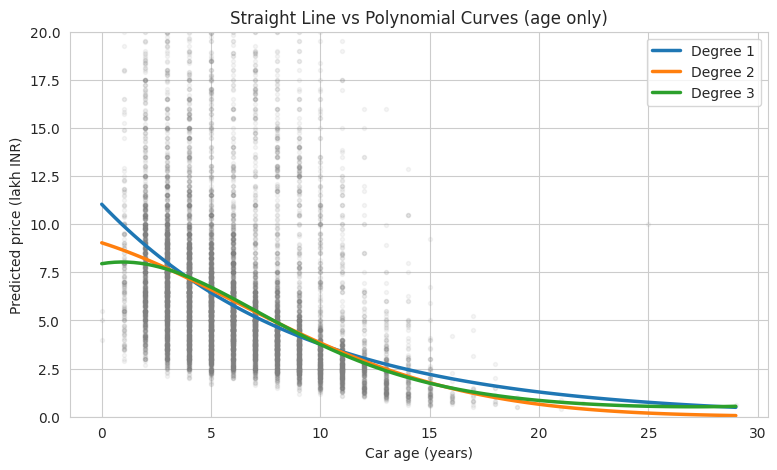

In [10]:
age_train = X_train[["vehicle_age"]]
grid = pd.DataFrame({"vehicle_age": np.linspace(0, X_train["vehicle_age"].max(), 100)})

plt.figure(figsize=(9, 5))
plt.scatter(X_train["vehicle_age"], np.exp(y_train) / LAKH, alpha=0.08, s=8, color="gray")

for degree in [1, 2, 3]:
    m = make_pipeline(PolynomialFeatures(degree=degree, include_bias=False), LinearRegression())
    m.fit(age_train, y_train)
    plt.plot(grid["vehicle_age"], np.exp(m.predict(grid)) / LAKH, linewidth=2.5, label=f"Degree {degree}")

plt.ylim(0, 20)
plt.xlabel("Car age (years)")
plt.ylabel("Predicted price (lakh INR)")
plt.title("Straight Line vs Polynomial Curves (age only)")
plt.legend()
plt.show()

**Insight:** All three curves fall as the car gets older. Because the model predicts the log of the price, even degree 1 gives a curve in rupees. The difference is at the two ends: degree 1 overestimates the newest cars (about 11 lakh at age 0), while degrees 2 and 3 follow the data better for both very new and very old cars.

## 6. Full Model: Compare Polynomial Degrees

Now all features are used. The pipeline does three things:
1. **Numeric features** (age, km, engine, power) are scaled with `StandardScaler`, then expanded into polynomial terms. For example, degree 2 adds age², age × km, and so on.
2. **Categorical features** (brand, fuel, transmission, seller) are converted to 0/1 columns with `OneHotEncoder`.
3. **Ridge regression** fits a linear model on all these columns. Ridge adds a small penalty that stops the coefficients from growing too large, which reduces overfitting.

I compare degrees 1 to 4 using:
- **Train vs Test R²**, to detect overfitting
- **5-fold cross-validated R²** on the training set
- **MAE in rupees** and **median % error**, which are easier to understand than R²

R² is calculated on the log price, because that is what the model predicts. MAE and % error are calculated in real rupees.

In [11]:
def make_model(degree):
    numeric_part = make_pipeline(
        StandardScaler(),
        PolynomialFeatures(degree=degree, include_bias=False),
    )
    preprocess = ColumnTransformer(
        [
            ("num", numeric_part, NUM_COLS),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS),
        ],
        sparse_threshold=0,
    )
    return make_pipeline(preprocess, Ridge(alpha=1.0))


def report(model, X_data, y_log):
    pred_log = model.predict(X_data)
    pred = np.exp(pred_log)
    actual = np.exp(y_log)
    return {
        "R2": r2_score(y_log, pred_log),
        "MAE (INR)": mean_absolute_error(actual, pred),
        "Median % error": np.median(np.abs(pred - actual) / actual) * 100,
    }

In [12]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {}
rows = []
for degree in [1, 2, 3, 4]:
    model = make_model(degree)
    cv_scores = cross_val_score(model, X_train, y_train, cv=kf, scoring="r2", n_jobs=-1)
    model.fit(X_train, y_train)
    models[degree] = model

    train_r = report(model, X_train, y_train)
    test_r = report(model, X_test, y_test)
    rows.append({
        "Degree": degree,
        "Train R2": train_r["R2"],
        "CV R2 (mean)": cv_scores.mean(),
        "Test R2": test_r["R2"],
        "Test MAE (INR)": test_r["MAE (INR)"],
        "Test median % error": test_r["Median % error"],
    })

results = pd.DataFrame(rows)
results.round(3)

,Degree,Train R2,CV R2 (mean),Test R2,Test MAE (INR),Test median % error
0,1,0.883,0.882,0.875,137569.608,14.081
1,2,0.902,0.900,0.895,116374.703,12.965
2,3,0.906,0.902,0.900,116611.221,12.614
3,4,0.910,0.902,0.899,112920.203,12.407


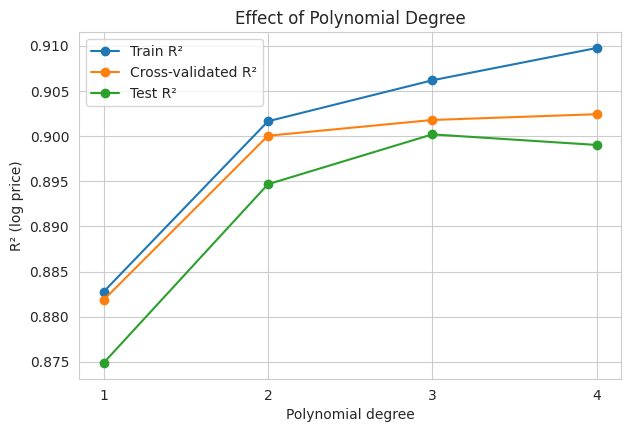

In [13]:
plt.figure(figsize=(7, 4.5))
plt.plot(results["Degree"], results["Train R2"], marker="o", label="Train R²")
plt.plot(results["Degree"], results["CV R2 (mean)"], marker="o", label="Cross-validated R²")
plt.plot(results["Degree"], results["Test R2"], marker="o", label="Test R²")
plt.xticks([1, 2, 3, 4])
plt.xlabel("Polynomial degree")
plt.ylabel("R² (log price)")
plt.title("Effect of Polynomial Degree")
plt.legend()
plt.show()

**How to read this:** As the degree goes up, the model can bend more, so Train R² keeps rising. The important lines are Cross-validated R² and Test R². If they stop rising while Train R² keeps climbing, the model has started to overfit.

**Result:** Polynomial terms clearly beat the straight line. Moving from degree 1 to degree 2 raised Test R² from 0.875 to 0.895 and cut the median error from 14.1% to 13.0%. Degrees 3 and 4 gave only a tiny extra gain (cross-validated R² of 0.902 for both), while Train R² kept rising (0.906 to 0.910), so going beyond degree 3 adds complexity without a real benefit. Degree 4 was selected because its cross-validated score was marginally the highest.

## 7. Pick the Best Degree

The best degree is chosen using **cross-validation**, not the test set, so the test set stays a final unseen check.

In [14]:
best_degree = int(results.loc[results["CV R2 (mean)"].idxmax(), "Degree"])
best_model = models[best_degree]
print("Best polynomial degree (by cross-validated R²):", best_degree)

final = report(best_model, X_test, y_test)
print(f"Test R² (log price):   {final['R2']:.3f}")
print(f"Test MAE:              about Rs {final['MAE (INR)']:,.0f}")
print(f"Median % error:        about {final['Median % error']:.1f}%")

Best polynomial degree (by cross-validated R²): 4
Test R² (log price):   0.899
Test MAE:              about Rs 112,920
Median % error:        about 12.4%


## 8. What Drives the Price?

For the straight-line model (degree 1), each numeric coefficient shows how much the price changes, in percent, when that feature goes up by **one standard deviation**, with the other features held constant. This is easy to read because the target is a log price.

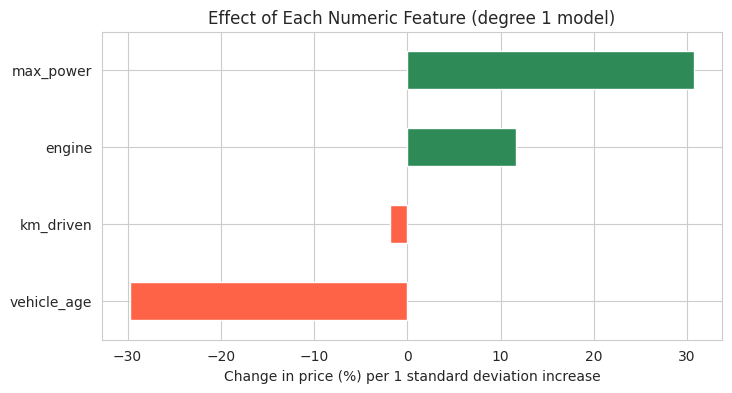

,0
vehicle_age,-29.7
km_driven,-1.9
engine,11.7
max_power,30.7


In [15]:
linear = models[1]
coefs = linear.named_steps["ridge"].coef_[:len(NUM_COLS)]
effect_pct = pd.Series((np.exp(coefs) - 1) * 100, index=NUM_COLS).sort_values()

plt.figure(figsize=(8, 4))
effect_pct.plot(kind="barh", color=["tomato" if v < 0 else "seagreen" for v in effect_pct])
plt.xlabel("Change in price (%) per 1 standard deviation increase")
plt.title("Effect of Each Numeric Feature (degree 1 model)")
plt.show()
effect_pct.round(1)

**Note:** Engine size and power are correlated with each other, so their individual effects should not be read as cause and effect.

## 9. Best Model: Residual Analysis

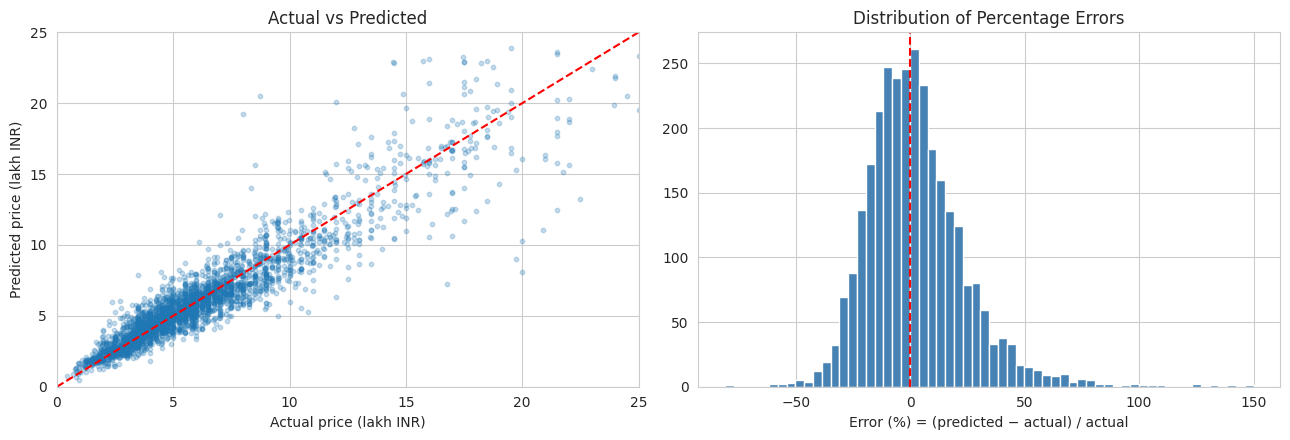

In [16]:
pred = np.exp(best_model.predict(X_test))
actual = np.exp(y_test)
pct_error = (pred - actual) / actual * 100

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].scatter(actual / LAKH, pred / LAKH, alpha=0.25, s=10)
top = 25
ax[0].plot([0, top], [0, top], "r--")
ax[0].set_xlim(0, top)
ax[0].set_ylim(0, top)
ax[0].set_xlabel("Actual price (lakh INR)")
ax[0].set_ylabel("Predicted price (lakh INR)")
ax[0].set_title("Actual vs Predicted")

ax[1].hist(pct_error.clip(-100, 150), bins=60, color="steelblue", edgecolor="white")
ax[1].axvline(0, color="r", linestyle="--")
ax[1].set_xlabel("Error (%) = (predicted − actual) / actual")
ax[1].set_title("Distribution of Percentage Errors")

plt.tight_layout()
plt.show()

In [17]:
# Where does the model make the biggest mistakes?
bands = pd.qcut(actual, q=4, labels=["Cheapest 25%", "Lower-mid", "Upper-mid", "Most expensive 25%"])
error_by_band = (
    pd.DataFrame({"band": bands, "abs_pct_error": pct_error.abs()})
    .groupby("band", observed=True)["abs_pct_error"].median()
    .round(1)
)
print("Median absolute % error by price band:")
print(error_by_band)

Median absolute % error by price band:
band
Cheapest 25%          16.0
Lower-mid             12.0
Upper-mid             10.0
Most expensive 25%    13.0
Name: abs_pct_error, dtype: float64


**What the plots show:** Predictions follow the red line closely for cars up to about 10 lakh, and the error histogram is centered near zero. The model is weakest for the cheapest 25% of cars (median error 16%) and strongest for the upper-middle price band (10%). Expensive cars above about 15 lakh are scattered more widely.

## 10. Example Prediction

In [18]:
sample_car = X_test.iloc[[0]]
pred_price = np.exp(best_model.predict(sample_car)[0])
actual_price = np.exp(y_test.iloc[0])

print(sample_car.T)
print(f"\nPredicted price: Rs {pred_price:,.0f}")
print(f"Actual price:    Rs {actual_price:,.0f}")

                         8843
vehicle_age                 6
km_driven               65000
engine                   1248
max_power                88.5
brand                  Maruti
fuel_type              Diesel
transmission_type      Manual
seller_type        Individual

Predicted price: Rs 557,156
Actual price:    Rs 475,000


## 11. Export the Model for the Website

A website cannot run scikit-learn, but a polynomial regression is just arithmetic: scale the numbers, build the polynomial terms, multiply by the coefficients, and add the intercept. So the learned numbers are saved to `model.json`, and the web page repeats the same steps in JavaScript.

In [19]:
pre = best_model.named_steps["columntransformer"]
ridge = best_model.named_steps["ridge"]
num_pipe = pre.named_transformers_["num"]
scaler = num_pipe.named_steps["standardscaler"]
poly = num_pipe.named_steps["polynomialfeatures"]
ohe = pre.named_transformers_["cat"]

model_json = {
    "degree": best_degree,
    "num_cols": NUM_COLS,
    "mean": scaler.mean_.tolist(),
    "scale": scaler.scale_.tolist(),
    "powers": poly.powers_.tolist(),
    "cat_cols": CAT_COLS,
    "categories": [[str(v) for v in cats] for cats in ohe.categories_],
    "coef": ridge.coef_.tolist(),
    "intercept": float(ridge.intercept_),
    "ranges": {c: [float(np.floor(X_train[c].min())), float(np.ceil(X_train[c].max()))] for c in NUM_COLS},
    "defaults_num": {c: float(round(X_train[c].median())) for c in NUM_COLS},
    "defaults_cat": {c: str(X_train[c].mode()[0]) for c in CAT_COLS},
    "median_pct_error": round(float(final["Median % error"]), 1),
}

with open("model.json", "w", encoding="utf-8") as f:
    json.dump(model_json, f, separators=(",", ":"), ensure_ascii=False)

print("model.json size: %.1f KB" % (os.path.getsize("model.json") / 1e3))

# Values for checking the website
check_car = X_test.iloc[0]
print("\nType these values into the website:")
for name, val in check_car.items():
    print(name, ":", val)
print("\nNotebook prediction: Rs " + format(round(float(np.exp(best_model.predict(X_test.iloc[[0]])[0]))), ","))

try:
    from google.colab import files
    files.download("model.json")
except ImportError:
    pass

model.json size: 3.7 KB

Type these values into the website:
vehicle_age : 6
km_driven : 65000
engine : 1248
max_power : 88.5
brand : Maruti
fuel_type : Diesel
transmission_type : Manual
seller_type : Individual

Notebook prediction: Rs 557,156


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Results Summary

In [20]:
print(f"Best polynomial degree:    {best_degree}")
print(f"Straight-line (degree 1):  Test R² {results.loc[0, 'Test R2']:.3f}, median error {results.loc[0, 'Test median % error']:.1f}%")
print(f"Best model (degree {best_degree}):    Test R² {final['R2']:.3f}, median error {final['Median % error']:.1f}%")
print(f"Average error (MAE):       about Rs {final['MAE (INR)']:,.0f}")

Best polynomial degree:    4
Straight-line (degree 1):  Test R² 0.875, median error 14.1%
Best model (degree 4):    Test R² 0.899, median error 12.4%
Average error (MAE):       about Rs 112,920


## 13. Conclusion, Limitations, and Next Steps

**Conclusion:** Polynomial regression predicted used-car prices better than a linear (degree 1) model. The best model (degree 4) reached a Test R² of 0.899 on the log price, compared with 0.875 for the straight line. Its median error is about 12.4% of the car’s price (14.1% for the straight line), and its average error is about 1.13 lakh rupees, compared with 1.38 lakh for the straight line. Most of the improvement came from degree 2, and degrees 3 and 4 performed almost the same, so a simpler degree 2 or 3 model would also be a reasonable choice. The average error in rupees is pulled up by expensive cars, where the same percentage error means a larger amount.

**Limitations**
- The data comes from CarDekho listings from one period of time, so prices do not match today's market.
- Only mainstream cars are covered (up to 50 lakh rupees), so the model is not reliable for luxury cars.
- Condition, accident history, colour, city, and trim level are not in the data, but all of them affect price.
- The model uses the brand but not the exact model of a car (for example, it cannot tell a base Swift from a top-end one).

**Next steps**
- Try Random Forest or Gradient Boosting and compare with the polynomial model
- Add the car model name as a feature
- Tune the Ridge `alpha` value with `GridSearchCV`